In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv(
    "../data/processed/terengganu_coastal_erosion_transects_144.csv"
)

df_valid = df[df["Is_Protected"] == 0].copy()

print("Total points:", len(df))
print("Non-protected points:", len(df_valid))
print("Protected points:", df["Is_Protected"].sum())

Total points: 2775
Non-protected points: 2766
Protected points: 9


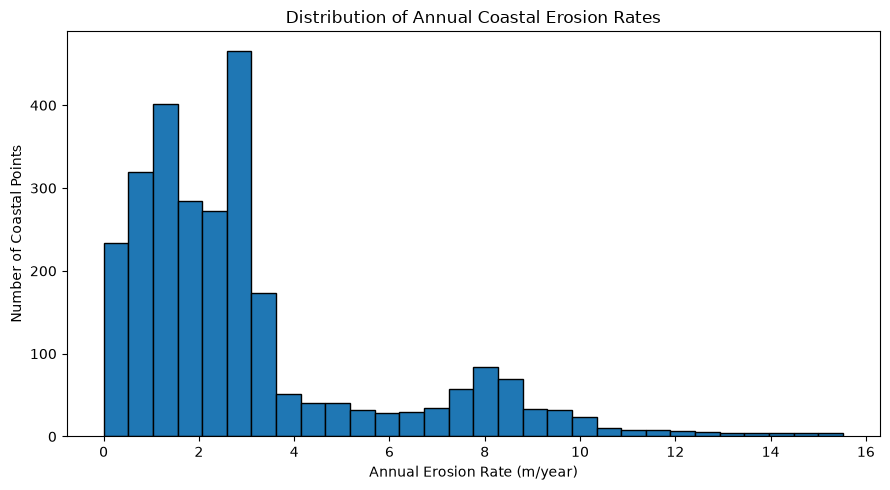

Mean erosion rate: 3.08
Median erosion rate: 2.27


In [2]:
# Step 2: Annual erosion rate distribution

plt.figure(figsize=(9, 5))

plt.hist(
    df_valid["Annual_Erosion_Rate_m_yr"],
    bins=30,
    edgecolor="black"
)

plt.xlabel("Annual Erosion Rate (m/year)")
plt.ylabel("Number of Coastal Points")
plt.title("Distribution of Annual Coastal Erosion Rates")

plt.tight_layout()
plt.show()

print("Mean erosion rate:",
      round(df_valid["Annual_Erosion_Rate_m_yr"].mean(), 2))

print("Median erosion rate:",
      round(df_valid["Annual_Erosion_Rate_m_yr"].median(), 2))

C:\Users\dator\AppData\Local\Temp\ipykernel_2332\4216631699.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(


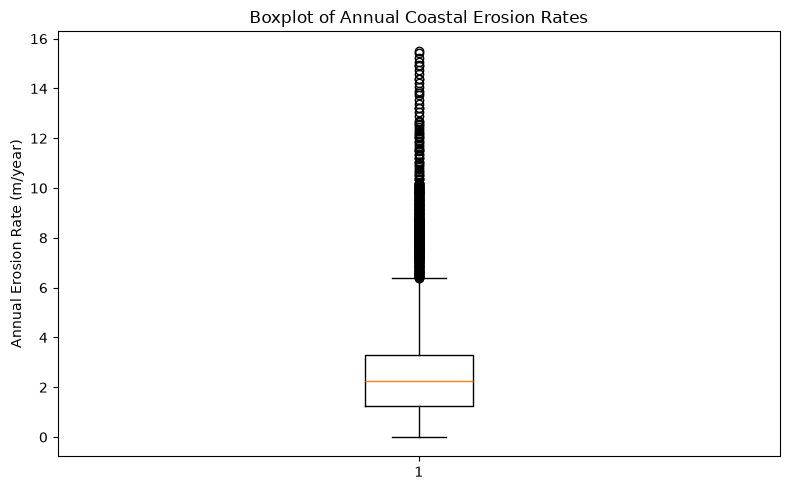

Maximum erosion rate: 15.52
Minimum erosion rate: 0.0


In [3]:
# Step 3: Annual erosion rate boxplot

plt.figure(figsize=(8, 5))

plt.boxplot(
    df_valid["Annual_Erosion_Rate_m_yr"],
    vert=True
)

plt.ylabel("Annual Erosion Rate (m/year)")
plt.title("Boxplot of Annual Coastal Erosion Rates")

plt.tight_layout()
plt.show()

print("Maximum erosion rate:",
      df_valid["Annual_Erosion_Rate_m_yr"].max())

print("Minimum erosion rate:",
      df_valid["Annual_Erosion_Rate_m_yr"].min())

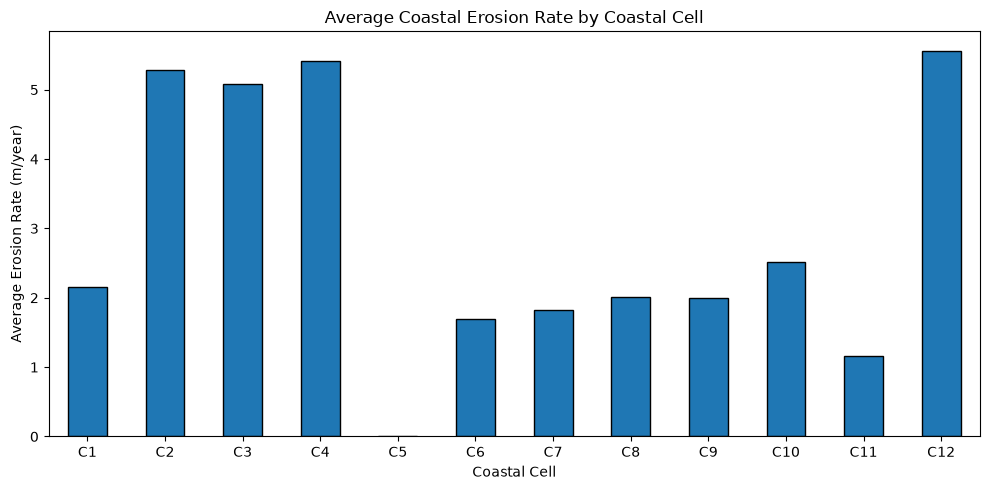

Average erosion rate by coastal cell:
Coastal_Cell
C1     2.15
C2     5.29
C3     5.08
C4     5.42
C5      NaN
C6     1.70
C7     1.83
C8     2.02
C9     1.99
C10    2.52
C11    1.16
C12    5.56
Name: Annual_Erosion_Rate_m_yr, dtype: float64


In [ ]:
# Step 4: Average erosion rate by coastal cell

cell_erosion = (
    df_valid.groupby("Coastal_Cell")["Annual_Erosion_Rate_m_yr"]
    .mean()
    .reindex([f"C{i}" for i in range(1, 13)])
)

plt.figure(figsize=(10, 5))

cell_erosion.plot(
    kind="bar",
    edgecolor="black"
)

plt.xlabel("Coastal Cell")
plt.ylabel("Average Erosion Rate (m/year)")
plt.title("Average Coastal Erosion Rate by Coastal Cell")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print("Average erosion rate by coastal cell:")
print(cell_erosion.round(2))

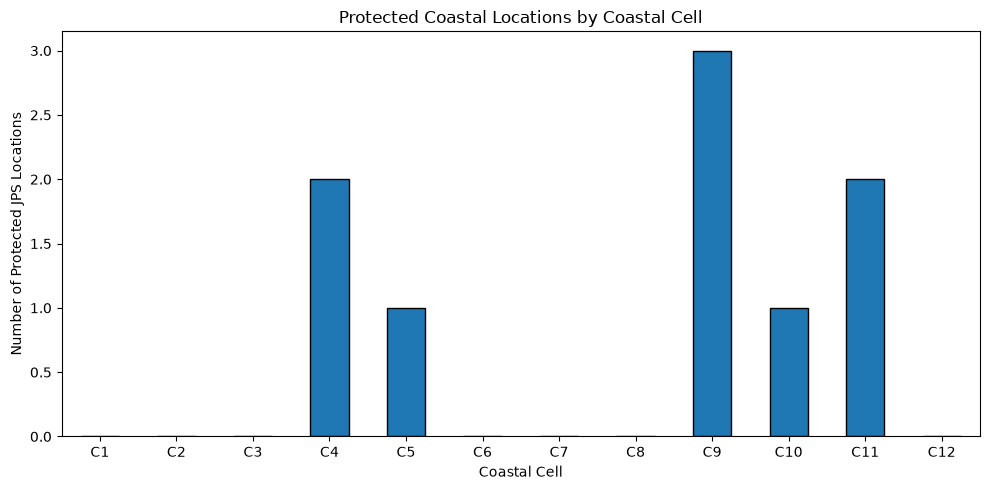

Total protected locations: 9

Protected locations by coastal cell:
Coastal_Cell
C4     2
C5     1
C9     3
C10    1
C11    2
Name: count, dtype: int64


In [6]:
# Step 5: Protected locations by coastal cell

df_protected = df[
    (df["Is_Protected"] == 1) &
    (df["Source_Type"] == "JPS_Original")
]

protected_counts = (
    df_protected["Coastal_Cell"]
    .value_counts()
    .reindex([f"C{i}" for i in range(1, 13)], fill_value=0)
)

plt.figure(figsize=(10, 5))

protected_counts.plot(
    kind="bar",
    edgecolor="black"
)

plt.xlabel("Coastal Cell")
plt.ylabel("Number of Protected JPS Locations")
plt.title("Protected Coastal Locations by Coastal Cell")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print("Total protected locations:", len(df_protected))

print("\nProtected locations by coastal cell:")
print(protected_counts[protected_counts > 0])

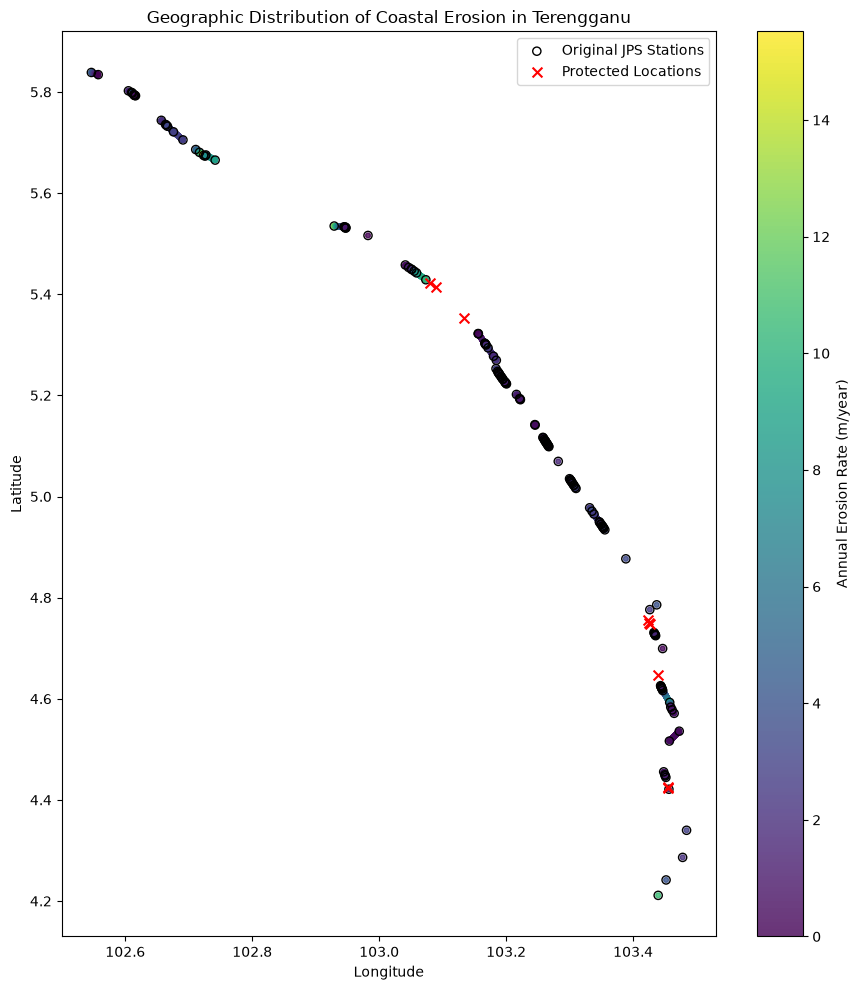

In [9]:
# Step 6: Geographic distribution of coastal erosion

df_original = df[
    (df["Source_Type"] == "JPS_Original") &
    (df["Is_Protected"] == 0)
]

df_protected = df[df["Is_Protected"] == 1]

plt.figure(figsize=(9, 10))

# Plot non-protected coastal points
scatter = plt.scatter(
    df_valid["Longitude_DD"],
    df_valid["Latitude_DD"],
    c=df_valid["Annual_Erosion_Rate_m_yr"],
    cmap="viridis",
    s=12,
    alpha=0.8
)

# Highlight original JPS stations
plt.scatter(
    df_original["Longitude_DD"],
    df_original["Latitude_DD"],
    facecolors="none",
    edgecolors="black",
    s=35,
    label="Original JPS Stations"
)

# Highlight protected locations
plt.scatter(
    df_protected["Longitude_DD"],
    df_protected["Latitude_DD"],
    color="red",
    marker="x",
    s=50,
    label="Protected Locations"
)

plt.colorbar(
    scatter,
    label="Annual Erosion Rate (m/year)"
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Geographic Distribution of Coastal Erosion in Terengganu")

plt.legend()
plt.tight_layout()
plt.show()

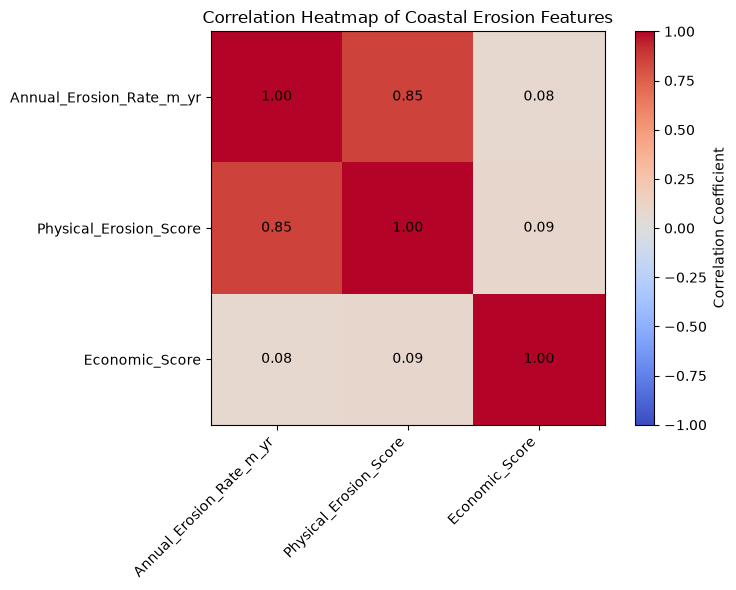

Correlation Matrix:
                          Annual_Erosion_Rate_m_yr  Physical_Erosion_Score  \
Annual_Erosion_Rate_m_yr                      1.00                    0.85   
Physical_Erosion_Score                        0.85                    1.00   
Economic_Score                                0.08                    0.09   

                          Economic_Score  
Annual_Erosion_Rate_m_yr            0.08  
Physical_Erosion_Score              0.09  
Economic_Score                      1.00  


In [10]:
# Step 7: Correlation heatmap

features = [
    "Annual_Erosion_Rate_m_yr",
    "Physical_Erosion_Score",
    "Economic_Score"
]

# Calculate correlation matrix
correlation = df_valid[features].corr()

plt.figure(figsize=(8, 6))

plt.imshow(
    correlation,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.colorbar(label="Correlation Coefficient")

plt.xticks(
    range(len(features)),
    features,
    rotation=45,
    ha="right"
)

plt.yticks(range(len(features)), features)

# Display correlation values
for i in range(len(features)):
    for j in range(len(features)):
        plt.text(
            j, i,
            f"{correlation.iloc[i, j]:.2f}",
            ha="center",
            va="center"
        )

plt.title("Correlation Heatmap of Coastal Erosion Features")
plt.tight_layout()
plt.show()

print("Correlation Matrix:")
print(correlation.round(2))